In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.0021307718291475224 + 0.0024217298218014954im -5.6474033906532165e-5 - 0.002264324897865137im … 0.005243186948182102 + 0.002301777211939959im 0.0021207238086391315 + 0.0059887973408932im; -0.0004453043693749688 + 0.002335945379591499im -0.0014276115958083203 - 0.0027573376534060835im … -0.0016220159294944943 - 0.0031304362742586725im 0.000491746916893906 + 0.0024417595711962283im; 0.001478431995632087 + 0.000924525802930465im 0.0007536023067703711 - 0.0018823359068504207im … 0.0006437013216505013 - 0.0008029621654675374im 0.0007851235317736589 - 0.005448659927442747im;;; -0.0036021522595540896 - 0.00023391348125121236im 0.0020142284054669563 - 0.003824702729252313im … -0.002945027575852115 + 0.0012653203084218552im -0.0034935717600508938 - 0.0024414717283069948im; 0.004903529269735471 - 0.0013932844959746921im -0.003121041170119541 - 0.0012290689934574596im … -6.43062836204735e-5 + 0.00022777979470180542im -

In [3]:
P=Onestep()
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)*0.1
W2=Generate_weight(hop)*0.1
W3=Generate_weight(hop)*0.1
W4=Generate_weight(hop)*0.1
W5=Generate_weight(hop)*0.1
W6=Generate_weight(hop)*0.1


9-element Vector{Spin_matrix}:
 [-0.08993224603759076 + 0.0im -0.1445393551678111 + 0.0im 0.188152500005339 + 0.0im -0.0007920782598082742 + 0.0im; -0.021052121912327443 + 0.0im -0.2460571872605113 + 0.0im -0.10315109887240421 + 0.0im 0.09186643116278548 + 0.0im; -0.13828824813108606 + 0.0im 0.11156850660613088 + 0.0im 0.05167463911765618 + 0.0im 0.0867980896886759 + 0.0im; -0.12212815600408736 + 0.0im -0.07719436181313966 + 0.0im -0.0021890687977096125 + 0.0im 0.11118239764332194 + 0.0im]
 [-0.08442958991972949 + 0.0im 0.00932789952302148 + 0.0im 0.2715379104460191 + 0.0im 0.008597679507637996 + 0.0im; -0.021171007459741268 + 0.0im 0.038968279131521566 + 0.0im 0.09196761247610667 + 0.0im -0.08538294488955443 + 0.0im; 0.19882210248782442 + 0.0im -0.02613868808791002 + 0.0im 0.13015653366414306 + 0.0im -0.0034398993283239285 + 0.0im; -0.11857426072257134 + 0.0im 0.005475987624607299 + 0.0im 0.07625801127597331 + 0.0im -0.06560130893005771 + 0.0im]
 [0.028181580006342084 + 0.0im 0.029511

In [4]:
# W1 = load("PTC_weight.jld2", "W")  # OK
# W2 = load("PTC_weight.jld2", "W")  # OK
# W3 = load("PTC_weight.jld2", "W")  # OK
# W4 = load("PTC_weight.jld2", "W")  # OK
# W5 = load("PTC_weight.jld2", "W")  # OK
# W6 = load("PTC_weight.jld2", "W")  # OK

In [ ]:
layer1=CPTC_Layer(hop,W1)
Norm=complexNormLayer()
layer2=PTC_Layer(hop,W2 ,true)
act=Softmax()
layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
layer3=Attention_Layer(CPTC_Layer(hop,W3),sqrt(length(x)),act,true)
layer4=PTC_Layer(hop,W4,true)
layer5=Attention_Layer(CPTC_Layer(hop,W5),sqrt(length(x)),act,true)
layer6=PTC_Layer(hop,W6)
layers=[layer1,Norm,layer2,Norm,layer3,Norm,layer4]
# layers=[layer1,Norm,layer2]

7-element Vector{LMP.Layer_types.Layer}:
 Attention_Layer(CPTC_Layer(Spin_matrix[[-0.05909128040842424 + 0.0im 0.07190876350728444 + 0.0im 0.01404512819958293 + 0.0im -0.08935183561644977 + 0.0im; 0.01112873753931505 + 0.0im 0.015495091867057921 + 0.0im -0.015966338267661726 + 0.0im -0.028875223209201814 + 0.0im; 0.0019732217292660883 + 0.0im -0.2155195129705283 + 0.0im 0.15781741932622162 + 0.0im 0.01307077304675845 + 0.0im; 0.03400965357662252 + 0.0im 0.04126063912984469 + 0.0im -0.05355606548373825 + 0.0im -0.2580345009701763 + 0.0im], [0.023006227993658025 + 0.0im -0.03988183558821015 + 0.0im -0.14900646105635582 + 0.0im 0.03741760855707206 + 0.0im; -0.13506910537429434 + 0.0im 0.06257722419110405 + 0.0im -0.11519854451530989 + 0.0im 0.16151962340436152 + 0.0im; 0.11404743539273227 + 0.0im 0.017188822430354914 + 0.0im -0.16846928209441822 + 0.0im 0.020921917709326776 + 0.0im; -0.1728615111560798 + 0.0im 0.018104793969181743 + 0.0im -0.06508268334333067 + 0.0im -0.008499255959591062

In [6]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-1.1428695540907943e-5 - 2.8665667899406114e-6im -4.063041266326685e-6 - 4.8138396862631415e-6im … -2.201680636266262e-6 - 1.1609910236404303e-5im -9.841436889342452e-6 - 7.344341353877458e-6im; 3.835995732426819e-6 - 1.2911103120813048e-7im -3.875437794602895e-6 - 5.471471031810002e-6im … -1.1989169676558892e-5 - 8.179504131149158e-6im -2.1080105960410653e-6 + 6.494913956513513e-6im; -1.4083374877707715e-6 - 5.270384967391626e-6im -2.738196566704677e-6 + 5.596095021960128e-6im … 1.1900098384961988e-6 + 4.086866237596708e-6im -8.15590208437196e-6 + 1.011155797138663e-5im;;; -1.3221457061260988e-5 - 6.1329881548972396e-6im 3.437720045743666e-6 + 9.132184502855443e-6im … 4.083135979661154e-6 + 1.4703604895943567e-6im 2.6175201280800786e-6 + 7.15719179219319e-6im; -3.925330623025846e-6 - 9.391180204172936e-6im 5.372414645924705e-6 + 5.5539649963100795e-6im … -1.1125059679564276e-6 - 5.146885923467762e-6im -9.34420

In [7]:
opt=Adam()
opt.α=0.05

0.05

In [8]:
println(norm2(layers(x)))

NaN + NaN*im


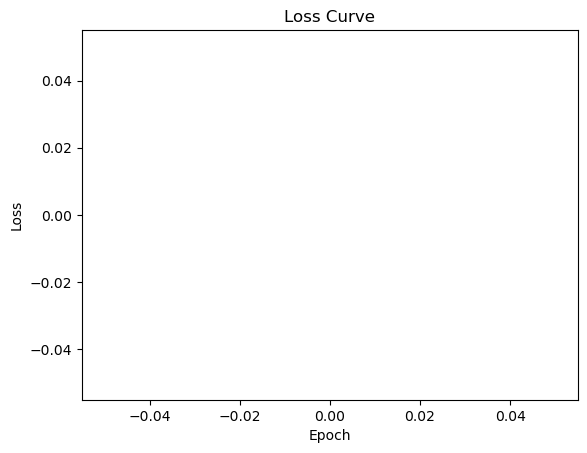

Epoch: 1, Loss: 1070.0189440539286 + 0.0im
Epoch: 2, Loss: 381.97365635904544 + 0.0im
Epoch: 3, Loss: 139.72339387358647 + 0.0im
Epoch: 4, Loss: 110.95330637508384 + 0.0im
Epoch: 5, Loss: 141.03584834336962 + 0.0im
Epoch: 6, Loss: 138.88557399694025 + 0.0im
Epoch: 7, Loss: 112.62060952537682 + 0.0im
Epoch: 8, Loss: 89.69034182378697 + 0.0im
Epoch: 9, Loss: 74.59520820591942 + 0.0im
Epoch: 10, Loss: 61.40992066059627 + 0.0im
Epoch: 11, Loss: 51.268190013383695 + 0.0im
Epoch: 12, Loss: 43.683996614868974 + 0.0im
Epoch: 13, Loss: 37.84706533405095 + 0.0im
Epoch: 14, Loss: 34.489984036723285 + 0.0im
Epoch: 15, Loss: 30.663658845913396 + 0.0im
Epoch: 16, Loss: 26.577327148234687 + 0.0im
Epoch: 17, Loss: 23.481246950262765 + 0.0im
Epoch: 18, Loss: 21.17375904657469 + 0.0im
Epoch: 19, Loss: 20.15433273890165 + 0.0im
Epoch: 20, Loss: 18.84020742101025 + 0.0im
Epoch: 21, Loss: 17.92972662603101 + 0.0im
Epoch: 22, Loss: 16.18645950517638 + 0.0im
Epoch: 23, Loss: 14.617424227360456 + 0.0im
Epoch:

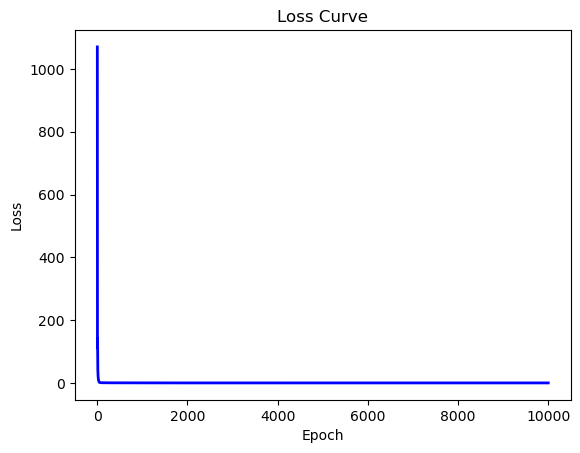

In [9]:
train(opt,layers,x,t,D,epochs=10000)